In [1]:
import sys; sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, matplotlib.pyplot as plt
from src.datos import cargar_obt, metadatos_datos
from src import pipeline as P

df = P.agregar_features(cargar_obt())
train, test = P.dividir_train_test(df)
X_tr, y_tr = P.preparar_X_y(train)
META = metadatos_datos(df)
mlflow = P.configurar_mlflow()
resultados = []
META

{'tabla_origen': 'CERVECERIA_DB.OBT.OBT_MERMA_LOTES',
 'fecha_corte': '2026-10-27',
 'hash_dataset': 'cded2e8b66972006',
 'n_filas': 221}

In [2]:
costo_fn, costo_fp = P.costos_por_lote(train)
print(f"Costo FN promedio (lotes con merma alta): ${costo_fn[train.merma_alta == 1].mean():.2f}")
print(f"Costo FP promedio (lotes normales):       ${costo_fp[train.merma_alta == 0].mean():.2f}")
print(f"Costos que usa el pipeline: FN ${P.COSTO_FN} | FP ${P.COSTO_FP}")

Costo FN promedio (lotes con merma alta): $108.07
Costo FP promedio (lotes normales):       $36.80
Costos que usa el pipeline: FN $108.07 | FP $36.8


Linea base 

In [3]:
from sklearn.dummy import DummyClassifier

lineas_base = {
    "base_ingenua_clase_mayoritaria": DummyClassifier(strategy="most_frequent"),         # siempre "merma alta"
    "base_negocio_sin_clarificante": DummyClassifier(strategy="constant", constant=0),   # proceso actual: nunca se usa clarificante
}
for nombre, m in lineas_base.items():
    run_id, met, _ = P.evaluar_y_registrar(nombre, m, X_tr, y_tr, "baseline", "dummy", META)
    resultados.append({"modelo": nombre, "fase": "baseline", "run_id": run_id, **met})
    print(f"{nombre}: ROC-AUC {met['cv_roc_auc_media']:.3f} | costo/lote ${met['cv_costo_media']:.1f}")

2026/11/18 13:43:49 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 13:43:50 INFO mlflow.tracking._tracking_service.client: 🏃 View run base_ingenua_clase_mayoritaria at: http://localhost:5050/#/experiments/1/runs/2346ef792b1648249ff603147eccd94a.
2026/11/18 13:43:50 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


base_ingenua_clase_mayoritaria: ROC-AUC 0.500 | costo/lote $12.4


2026/11/18 13:43:55 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 13:43:55 INFO mlflow.tracking._tracking_service.client: 🏃 View run base_negocio_sin_clarificante at: http://localhost:5050/#/experiments/1/runs/4290baa75c0241b994077e4c6ceef560.
2026/11/18 13:43:55 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


base_negocio_sin_clarificante: ROC-AUC 0.500 | costo/lote $71.5


5 modelos 

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

candidatos = {
    "logistica":              (LogisticRegression(max_iter=1000, random_state=P.SEMILLA), "lineal_regularizado"),
    "random_forest":          (RandomForestClassifier(random_state=P.SEMILLA), "bagging"),
    "hist_gradient_boosting": (HistGradientBoostingClassifier(random_state=P.SEMILLA), "boosting"),
    "mlp":                    (MLPClassifier(max_iter=2000, random_state=P.SEMILLA), "red_neuronal"),
    "svc":                    (SVC(probability=True, random_state=P.SEMILLA), "kernel"),
}
for nombre, (m, familia) in candidatos.items():
    run_id, met, _ = P.evaluar_y_registrar(nombre, m, X_tr, y_tr, "candidato", familia, META)
    resultados.append({"modelo": nombre, "fase": "candidato", "run_id": run_id, **met})
    print(f"{nombre}: ROC-AUC CV {met['cv_roc_auc_media']:.3f} ± {met['cv_roc_auc_std']:.3f} | brecha {met['brecha']:.3f} | costo/lote ${met['cv_costo_media']:.1f}")

2026/11/18 13:44:00 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 13:44:01 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistica at: http://localhost:5050/#/experiments/1/runs/39d4a122e01942d1957f3823c82dff7b.
2026/11/18 13:44:01 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


logistica: ROC-AUC CV 0.629 ± 0.152 | brecha 0.099 | costo/lote $29.3


2026/11/18 13:44:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 13:44:08 INFO mlflow.tracking._tracking_service.client: 🏃 View run random_forest at: http://localhost:5050/#/experiments/1/runs/8b7c47dce6a8494db8e384b9377a3a12.
2026/11/18 13:44:08 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


random_forest: ROC-AUC CV 0.632 ± 0.143 | brecha 0.368 | costo/lote $19.6


... (5 outputs left out)

mlp: ROC-AUC CV 0.604 ± 0.138 | brecha 0.395 | costo/lote $31.5


2026/11/18 13:44:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 13:44:29 INFO mlflow.tracking._tracking_service.client: 🏃 View run svc at: http://localhost:5050/#/experiments/1/runs/0954be6afbfc4c53a08c26bdb4aa9f4c.
2026/11/18 13:44:29 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.


svc: ROC-AUC CV 0.586 ± 0.134 | brecha 0.305 | costo/lote $20.1


Tablas y graficos 

,fase,train_roc_auc,cv_roc_auc_media,cv_roc_auc_std,brecha,cv_f1_media,cv_balanced_accuracy_media,cv_costo_media,segundos_entrenamiento
modelo,,,,,,,,,
random_forest,candidato,1.000,0.632,0.143,0.368,0.754,0.550,19.587,0.209
logistica,candidato,0.728,0.629,0.152,0.099,0.674,0.531,29.276,0.023
mlp,candidato,1.000,0.604,0.138,0.395,0.661,0.578,31.464,1.377
hist_gradient_boosting,candidato,0.760,0.587,0.200,0.172,0.736,0.601,22.568,0.122
svc,candidato,0.891,0.586,0.134,0.305,0.750,0.566,20.095,0.030
base_ingenua_clase_mayoritaria,baseline,0.500,0.500,0.000,0.000,0.788,0.500,12.436,0.018
base_negocio_sin_clarificante,baseline,0.500,0.500,0.000,0.000,0.000,0.500,71.550,0.017


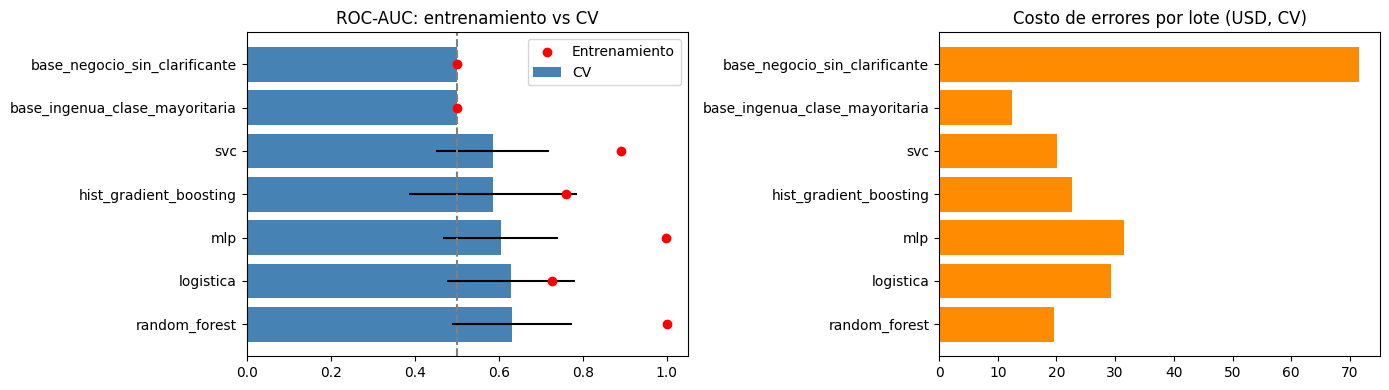

In [5]:
tabla = pd.DataFrame(resultados).set_index("modelo")
cols = ["fase", "train_roc_auc", "cv_roc_auc_media", "cv_roc_auc_std", "brecha",
        "cv_f1_media", "cv_balanced_accuracy_media", "cv_costo_media", "segundos_entrenamiento"]
tabla = tabla[cols].sort_values("cv_roc_auc_media", ascending=False)
display(tabla.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(tabla.index, tabla["cv_roc_auc_media"], xerr=tabla["cv_roc_auc_std"], color="steelblue", label="CV")
ax[0].scatter(tabla["train_roc_auc"], tabla.index, color="red", zorder=3, label="Entrenamiento")
ax[0].axvline(0.5, ls="--", color="gray"); ax[0].set_title("ROC-AUC: entrenamiento vs CV"); ax[0].legend()
ax[1].barh(tabla.index, tabla["cv_costo_media"], color="darkorange"); ax[1].set_title("Costo de errores por lote (USD, CV)")
plt.tight_layout(); plt.savefig("../docs/figs/06_candidatos.png", dpi=150); plt.show()
tabla.to_csv("../docs/resultados_candidatos.csv")

In [6]:
import re, time, requests, numpy as np

OLLAMA_URL = "http://localhost:11434/api/generate"
MODELO_LLM = "llama3.2:1b"

def contexto_historico(tr):
    """Resumen de los lotes de ENTRENAMIENTO que se le da al LLM (nunca ve los de validación)."""
    por_cepa = tr.groupby("cepa")["merma_alta"].mean()
    nueva = tr[tr.generacion_levadura == 0]["merma_alta"].mean()
    reusada = tr[tr.generacion_levadura > 0]["merma_alta"].mean()
    temp_alta = tr[tr.temporada_alta == 1]["merma_alta"].mean()
    temp_normal = tr[tr.temporada_alta == 0]["merma_alta"].mean()
    cepas = ", ".join(f"{c}: {v:.0%}" for c, v in por_cepa.items())
    return (
        "Eres un experto en producción de cerveza. Un lote tiene MERMA ALTA si pierde más del 5 % "
        "del volumen planificado en filtración.\n"
        "Datos históricos de la planta:\n"
        f"- El {tr['merma_alta'].mean():.0%} de los lotes tuvo merma alta.\n"
        f"- Por cepa: {cepas}.\n"
        f"- Levadura nueva (generación 0): {nueva:.0%}; levadura reutilizada: {reusada:.0%}.\n"
        f"- Temporada alta (abril, mayo, junio, agosto): {temp_alta:.0%}; resto del año: {temp_normal:.0%}.\n"
        "Responde SOLO con un número entero de 0 a 100: la probabilidad de que el lote tenga merma alta.\n"
    )

def describir_lote(f):
    gen = "desconocida" if pd.isna(f.generacion_levadura) else int(f.generacion_levadura)
    temporada = "temporada alta" if f.temporada_alta == 1 else "temporada normal"
    return (f"Lote: estilo {f.estilo}, cepa {f.cepa}, generación de levadura {gen}, "
            f"mes de cocción {int(f.coccion_mes)} ({temporada}), "
            f"{int(f.carga_planta_14d)} lotes cocinados en los 14 días anteriores.\nProbabilidad:")

def preguntar_llm(prompt, intentos=3):
    for i in range(intentos):
        try:
            r = requests.post(OLLAMA_URL, json={"model": MODELO_LLM, "prompt": prompt, "stream": False,
                                                "keep_alive": "30m",
                                                "options": {"temperature": 0, "seed": P.SEMILLA,
                                                            "num_predict": 6, "num_ctx": 1024}},
                              timeout=300)
            texto = r.json()["response"]
            numero = re.search(r"\d+", texto)
            return (min(int(numero.group()), 100) / 100 if numero else 0.5), texto
        except Exception as e:
            print(f"  reintento {i+1}: {type(e).__name__}")
            time.sleep(5)
    return 0.5, "SIN_RESPUESTA"          # si falla 3 veces, probabilidad neutra (queda registrado)

# Prueba con 3 lotes
ctx = contexto_historico(train)
print(ctx)
for _, fila in train.tail(3).iterrows():
    t0 = time.time()
    prob, texto = preguntar_llm(ctx + describir_lote(fila))
    print(describir_lote(fila).replace("\nProbabilidad:", ""),
          f"→ LLM: '{texto.strip()}' = {prob:.2f} | real: {fila.merma_alta} | {time.time()-t0:.1f} s")

Eres un experto en producción de cerveza. Un lote tiene MERMA ALTA si pierde más del 5 % del volumen planificado en filtración.
Datos históricos de la planta:
- El 64% de los lotes tuvo merma alta.
- Por cepa: BE-256: 100%, K-97: 75%, US-05: 61%, W34/70: 63%.
- Levadura nueva (generación 0): 91%; levadura reutilizada: 62%.
- Temporada alta (abril, mayo, junio, agosto): 69%; resto del año: 59%.
Responde SOLO con un número entero de 0 a 100: la probabilidad de que el lote tenga merma alta.

Lote: estilo Iguana, cepa K-97, generación de levadura 0, mes de cocción 8 (temporada alta), 12 lotes cocinados en los 14 días anteriores. → LLM: 'Para determinar la probabilidad' = 0.50 | real: 1 | 10.6 s
Lote: estilo Oktoberfest, cepa W34/70, generación de levadura 2, mes de cocción 8 (temporada alta), 12 lotes cocinados en los 14 días anteriores. → LLM: 'Para determinar la probabilidad' = 0.50 | real: 1 | 2.1 s
Lote: estilo American Lager, cepa W34/70, generación de levadura 1, mes de cocción 8 (te

Evaluacion de LLM y registro en MLFLOW

In [7]:
from sklearn.metrics import roc_auc_score, f1_score, balanced_accuracy_score

UMBRAL_LLM = 0.5
metricas_pliegue, filas_pred = [], []
t_inicio = time.time()

for k, (i_tr, i_va) in enumerate(P.esquema_cv().split(train), 1):
    tr, va = train.iloc[i_tr], train.iloc[i_va]
    ctx = contexto_historico(tr)                       # el LLM solo ve estadísticas del pasado
    probs = []
    for j, (_, fila) in enumerate(va.iterrows(), 1):
        prob, texto = preguntar_llm(ctx + describir_lote(fila))
        probs.append(prob)
        filas_pred.append({"pliegue": k, "numero_documento": fila.numero_documento,
                           "respuesta_llm": texto.strip(), "prob": prob, "real": fila.merma_alta})
    probs = np.array(probs); pred = (probs >= UMBRAL_LLM).astype(int); y_va = va["merma_alta"].values
    metricas_pliegue.append({
        "roc_auc": roc_auc_score(y_va, probs) if len(set(y_va)) > 1 else np.nan,
        "f1": f1_score(y_va, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_va, pred),
        "costo": P.costo_negocio(y_va, pred),
    })
    print(f"Pliegue {k} listo ({len(va)} lotes) | ROC-AUC {metricas_pliegue[-1]['roc_auc']:.3f} | {time.time()-t_inicio:.0f} s acumulados")

mp = pd.DataFrame(metricas_pliegue)
met_llm = {f"cv_{m}_media": float(mp[m].mean()) for m in mp.columns}
met_llm |= {f"cv_{m}_std": float(mp[m].std(ddof=0)) for m in mp.columns}
met_llm["segundos_cv"] = time.time() - t_inicio
met_llm["segundos_entrenamiento"] = 0.0      # el LLM no se entrena: solo recibe el contexto

with mlflow.start_run(run_name="llm_llama3.2_1b") as run:
    mlflow.log_params({"modelo_llm": MODELO_LLM, "temperatura": 0, "umbral": UMBRAL_LLM,
                       "semilla": P.SEMILLA, "tipo": "prompting zero-shot con estadísticas del pliegue", **META})
    mlflow.log_metrics(met_llm)
    mlflow.set_tags({"fase": "candidato", "familia": "state_of_the_art_llm", "commit_git": P.commit_git(),
                     "esquema_cv": "TimeSeriesSplit(5)", "metrica_tecnica": P.METRICA_TECNICA})
    mlflow.log_text(contexto_historico(train) + describir_lote(train.iloc[-1]), "prompt_ejemplo.txt")
    mlflow.log_text(pd.DataFrame(filas_pred).to_csv(index=False), "predicciones_llm.csv")
    resultados.append({"modelo": "llm_llama3.2_1b", "fase": "candidato", "run_id": run.info.run_id,
                       "train_roc_auc": np.nan, "brecha": np.nan, **met_llm})

print(f"\nLLM: ROC-AUC CV {met_llm['cv_roc_auc_media']:.3f} ± {met_llm['cv_roc_auc_std']:.3f} | costo/lote ${met_llm['cv_costo_media']:.1f} | {met_llm['segundos_cv']/60:.1f} min")

Pliegue 1 listo (29 lotes) | ROC-AUC 0.500 | 44 s acumulados
Pliegue 2 listo (29 lotes) | ROC-AUC 0.500 | 86 s acumulados
Pliegue 3 listo (29 lotes) | ROC-AUC 0.500 | 128 s acumulados
Pliegue 4 listo (29 lotes) | ROC-AUC 0.500 | 173 s acumulados
Pliegue 5 listo (29 lotes) | ROC-AUC 0.500 | 227 s acumulados


2026/11/18 13:48:34 INFO mlflow.tracking._tracking_service.client: 🏃 View run llm_llama3.2_1b at: http://localhost:5050/#/experiments/1/runs/2ff4560eb0cf48af92d719e5173e550f.
2026/11/18 13:48:34 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5050/#/experiments/1.



LLM: ROC-AUC CV 0.500 ± 0.000 | costo/lote $12.4 | 3.8 min


Tablas y graficos final  

,fase,train_roc_auc,cv_roc_auc_media,cv_roc_auc_std,brecha,cv_f1_media,cv_balanced_accuracy_media,cv_costo_media,segundos_entrenamiento
modelo,,,,,,,,,
random_forest,candidato,1.000,0.632,0.143,0.368,0.754,0.550,19.587,0.209
logistica,candidato,0.728,0.629,0.152,0.099,0.674,0.531,29.276,0.023
mlp,candidato,1.000,0.604,0.138,0.395,0.661,0.578,31.464,1.377
hist_gradient_boosting,candidato,0.760,0.587,0.200,0.172,0.736,0.601,22.568,0.122
svc,candidato,0.891,0.586,0.134,0.305,0.750,0.566,20.095,0.030
base_ingenua_clase_mayoritaria,baseline,0.500,0.500,0.000,0.000,0.788,0.500,12.436,0.018
base_negocio_sin_clarificante,baseline,0.500,0.500,0.000,0.000,0.000,0.500,71.550,0.017
llm_llama3.2_1b,candidato,NaN,0.500,0.000,NaN,0.788,0.500,12.436,0.000


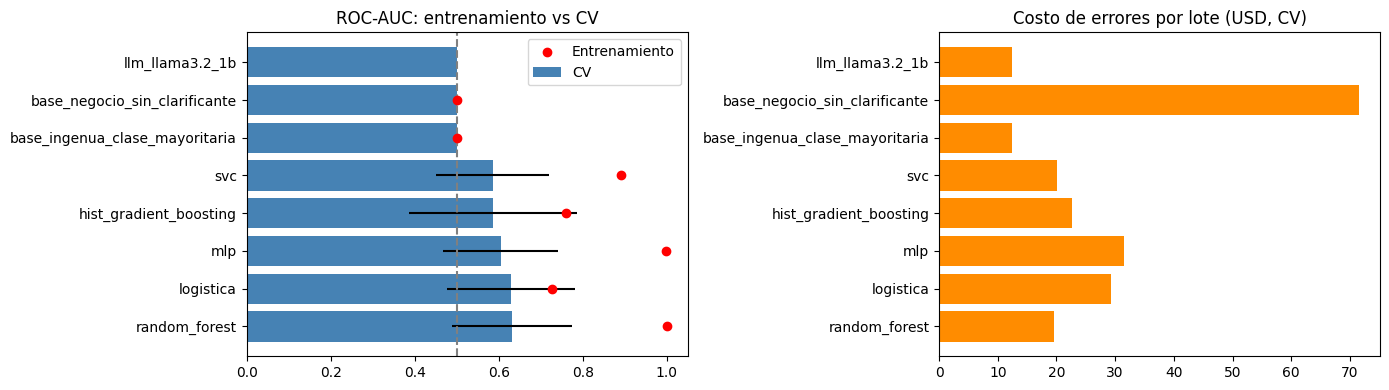

In [8]:
tabla = pd.DataFrame(resultados).set_index("modelo")
cols = ["fase", "train_roc_auc", "cv_roc_auc_media", "cv_roc_auc_std", "brecha",
        "cv_f1_media", "cv_balanced_accuracy_media", "cv_costo_media", "segundos_entrenamiento"]
tabla = tabla[cols].sort_values("cv_roc_auc_media", ascending=False)
display(tabla.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh(tabla.index, tabla["cv_roc_auc_media"], xerr=tabla["cv_roc_auc_std"], color="steelblue", label="CV")
ax[0].scatter(tabla["train_roc_auc"], tabla.index, color="red", zorder=3, label="Entrenamiento")
ax[0].axvline(0.5, ls="--", color="gray"); ax[0].set_title("ROC-AUC: entrenamiento vs CV"); ax[0].legend()
ax[1].barh(tabla.index, tabla["cv_costo_media"], color="darkorange"); ax[1].set_title("Costo de errores por lote (USD, CV)")
plt.tight_layout(); plt.savefig("../docs/figs/06_candidatos.png", dpi=150); plt.show()
tabla.to_csv("../docs/resultados_candidatos.csv")